<a href="https://colab.research.google.com/github/LalTamatar/Hackathon-file/blob/main/fashion_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow import keras

In [ ]:
print(tf.__version__)

2.21.0


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
mnist = keras.datasets.fashion_mnist

In [ ]:
type(mnist)

module

In [ ]:
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()


In [ ]:
X_train.shape, Y_train.shape

((60000, 28, 28), (60000,))

In [ ]:
X_test.shape, Y_test.shape

((10000, 28, 28), (10000,))

In [ ]:
np.max(X_train) #255 here signifies the white to black spectrum with 255 being the whitest and 0 being the blackest

np.uint8(255)

In [ ]:
np.mean(X_train)

np.float64(72.94035223214286)

#Data exploration

In [ ]:
X_train.shape

(60000, 28, 28)

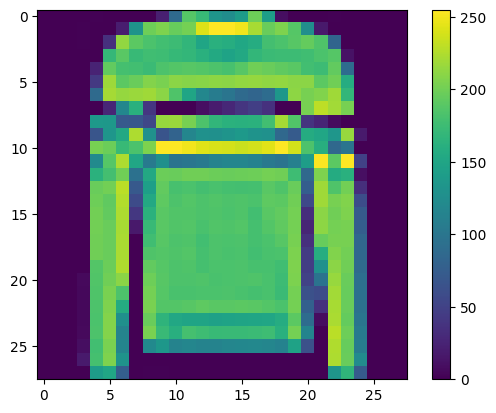

In [ ]:
plt.figure #creates a figure canvas
plt.imshow(X_train[5])
plt.colorbar()

In [ ]:
Y_train

array([9, 0, 0, ..., 3, 0, 5], dtype=uint8)

In [ ]:
X_train = X_train/255.0

In [ ]:
X_test = X_test/255.0 #Scaling the value down to between 0 and 1


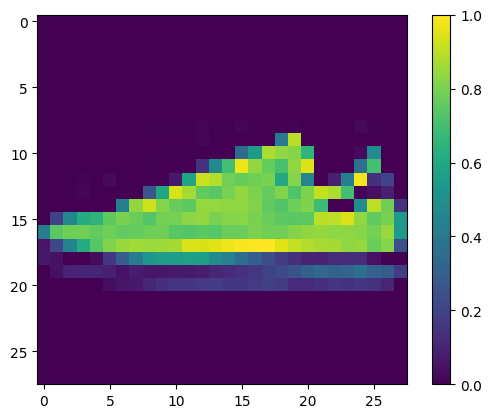

In [ ]:
plt.figure()
plt.imshow(X_train[6])
plt.colorbar()


#Building the model

In [ ]:
from keras import Sequential
from keras.layers import Flatten, Dense

In [ ]:
#if 2 or more hidden layers then it is called deep neural network
#model = Sequential()
#model.add(Flatten(input_shape=(28,28))) #here flatten is a layer withe the input size of 28*28
#model.add(Dense(128, activation ='relu')) #here activation functions are used to make the data non linear so that the predictions can become more accurate
#model.add(Dense(128, activation = 'relu'))
#model.add(Dense(10, activation ='softmax')) #10 represents the 10 classes


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
from keras.layers import Dropout

In [ ]:
import numpy as np
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)


from keras import layers
model = Sequential()

model.add(layers.Input(shape=(28,28,1)))

#adding random shifts and rotation to stop memorization aka overfitting

model.add(layers.RandomRotation(0.02, fill_mode='constant'))#tells the model to rotate the image by some degree and whatever corner is cut fill it with 0
model.add(layers.RandomTranslation(height_factor=0.02, width_factor =0.02, fill_mode='constant'))#same with this but here we are translating up and down

model.add(Flatten())

model.add(Dense(256, activation ='relu'))#increased the neurons in dense layer for better calcualtions
model.add(Dropout(0.2)) #prevent neurons from overrelying on specific pixels bu shutting down those neurons
model.add(Dense(10, activation="softmax"))

In [ ]:
 model.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation_3               │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_3            │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,530 (795.04 KB)

 Trainable params: 203,530 (795.04 KB)

 Non-trainable params: 0 (0.00 B)

#model compilation

*   Loss Function
*   Optimizer
*   Metrics






In [ ]:
from keras.optimizers import Adam

In [ ]:

model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])


In [ ]:
#model.fit(X_train, Y_train, epochs = 10, batch_size = 256) #here we made the batch size bigger in order to get more accuracy via diversity of input

In [ ]:
from keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', #watches the loss value
                                  patience = 8, #stops if it doesn't improve in 3 rounds
                                  restore_best_weights=True #roll back to the best weight we got with training
)
model.fit(X_train, Y_train, epochs = 100, batch_size=256, validation_data=(X_test, Y_test),callbacks = [early_stopping])#stops when callbacks comes up


Epoch 1/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8359 - loss: 0.4496 - val_accuracy: 0.8589 - val_loss: 0.3996
Epoch 2/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8397 - loss: 0.4411 - val_accuracy: 0.8474 - val_loss: 0.4179
Epoch 3/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8383 - loss: 0.4388 - val_accuracy: 0.8607 - val_loss: 0.3946
Epoch 4/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8402 - loss: 0.4376 - val_accuracy: 0.8572 - val_loss: 0.4053
Epoch 5/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8432 - loss: 0.4316 - val_accuracy: 0.8604 - val_loss: 0.3916
Epoch 6/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8429 - loss: 0.4300 - val_accuracy: 0.8638 - val_loss: 0.3932
Epoch 7/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8462 - loss: 0.4222 - val_accuracy: 0.8643 - val_loss: 0.3919
Epoch 8/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8455 - loss: 0.4212 - val_accu

In [ ]:
test_loss, test_acc = model.evaluate(X_test, Y_test)
print(f"Test Accuracy:{test_acc* 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8851 - loss: 0.3235
Test Accuracy:88.51%


In [ ]:
print("Train Max:", X_train.max())
print("Test Max:", X_test.max())



Train Max: 1.0
Test Max: 1.0
